# Exploratory Data Analysis

This notebook performs exploratory analysis on the cleaned and transformed e-commerce datasets.

The objective is to identify trends, patterns, relationships, and business insights that can support decision-making.

Analysis will be performed according to the grain of each dataset, with tables merged only when required by the business question.

## Data Loading

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

DATA_PATH = r'D:\Data_Analyst_Project\Online_Retail_Business_Analysis\01_Data\Processed_Data'

In [2]:
orders = pd.read_csv(rf'{DATA_PATH}\orders_clean.csv')
order_items = pd.read_csv(rf'{DATA_PATH}\order_items_clean.csv')
order_item_refunds = pd.read_csv(rf'{DATA_PATH}\order_item_refunds_clean.csv')
products = pd.read_csv(rf'{DATA_PATH}\products_clean.csv')
website_pageviews = pd.read_csv(rf'{DATA_PATH}\website_pageviews_clean.csv')
website_sessions = pd.read_csv(rf'{DATA_PATH}\website_sessions_clean.csv')

In [3]:
orders['created_at'] = pd.to_datetime(orders['created_at'])
order_items['created_at'] = pd.to_datetime(order_items['created_at'])
order_item_refunds['created_at'] = pd.to_datetime(order_item_refunds['created_at'])
products['created_at'] = pd.to_datetime(products['created_at'])
website_pageviews['created_at'] = pd.to_datetime(website_pageviews['created_at'])
website_sessions['created_at'] = pd.to_datetime(website_sessions['created_at'])

## Monthly Business Performance

In [4]:
monthly_performance = orders.groupby(orders['created_at'].dt.to_period('M')).agg(
                            total_orders=('order_id', 'count'),
                            total_revenue=('price_usd', 'sum'),
                            total_profit=('gross_profit', 'sum')
                        )

monthly_performance['AOV'] = monthly_performance['total_revenue'] / monthly_performance['total_orders']

monthly_performance

,total_orders,total_revenue,total_profit,AOV
created_at,,,,
2012-03,60,2999.40,1830.0,49.990000
2012-04,99,4949.01,3019.5,49.990000
2012-05,108,5398.92,3294.0,49.990000
2012-06,140,6998.60,4270.0,49.990000
2012-07,169,8448.31,5154.5,49.990000
2012-08,228,11397.72,6954.0,49.990000
2012-09,287,14347.13,8753.5,49.990000
2012-10,371,18546.29,11315.5,49.990000
2012-11,618,30893.82,18849.0,49.990000


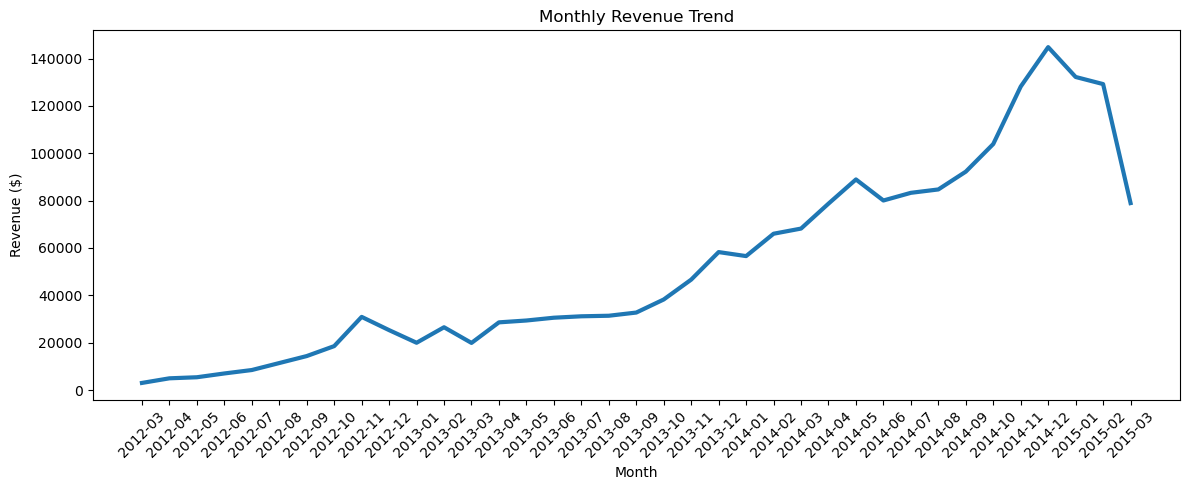

In [5]:
monthly_plot = monthly_performance.copy()
monthly_plot.index = monthly_plot.index.astype(str)

plt.figure(figsize=(12,5))

plt.plot(
    monthly_plot.index,
    monthly_plot['total_revenue'],
    linewidth=3
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue ($)')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Order Size Analysis

In [6]:
order_size_analysis = orders.groupby('items_purchased').agg(
    total_orders=('order_id', 'count'),
    avg_revenue=('price_usd', 'mean'),
    avg_profit=('gross_profit', 'mean')
)

order_size_analysis

,total_orders,avg_revenue,avg_profit
items_purchased,,,
1,24601,50.819397,31.482358
2,7712,89.250747,57.266857


## Did the proportion of two-item orders increase over time?

In [7]:
monthly_order_size_performance = orders.groupby(
    orders['created_at'].dt.to_period('M')
).agg(
    total_orders=('order_id', 'count'),
    total_two_item_orders=('items_purchased', lambda x: (x==2).sum()),
    total_revenue=('price_usd', 'sum'),
    total_profit=('gross_profit', 'sum')
)

monthly_order_size_performance['two_item_order_pct'] = (
    monthly_order_size_performance['total_two_item_orders'] / 
    monthly_order_size_performance['total_orders']
) * 100

monthly_order_size_performance

,total_orders,total_two_item_orders,total_revenue,total_profit,two_item_order_pct
created_at,,,,,
2012-03,60,0,2999.40,1830.0,0.000000
2012-04,99,0,4949.01,3019.5,0.000000
2012-05,108,0,5398.92,3294.0,0.000000
2012-06,140,0,6998.60,4270.0,0.000000
2012-07,169,0,8448.31,5154.5,0.000000
2012-08,228,0,11397.72,6954.0,0.000000
2012-09,287,0,14347.13,8753.5,0.000000
2012-10,371,0,18546.29,11315.5,0.000000
2012-11,618,0,30893.82,18849.0,0.000000


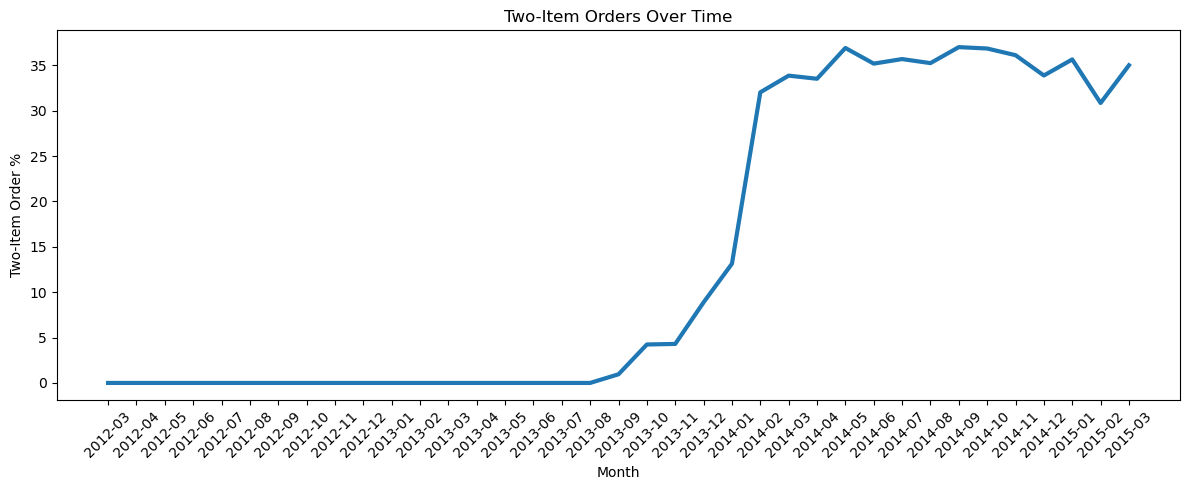

In [8]:
two_item_plot = monthly_order_size_performance.copy()
two_item_plot.index = two_item_plot.index.astype(str)

plt.figure(figsize=(12,5))

plt.plot(
    two_item_plot.index,
    two_item_plot['two_item_order_pct'],
    linewidth=3
)

plt.title('Two-Item Orders Over Time')
plt.xlabel('Month')
plt.ylabel('Two-Item Order %')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### The rise in AOV coincides with a substantial increase in two-item orders, suggesting that the shift toward multi-item purchasing contributed to higher order values.

## Which products are driving these two-item orders?

In [9]:
two_item_orders = orders[orders['items_purchased'] == 2]
two_item_orders = two_item_orders[['order_id']]
two_item_orders = two_item_orders.merge(order_items, on='order_id', how='left')
two_item_orders = two_item_orders.merge(products, on='product_id', how='left')
items_a = two_item_orders.copy()
items_b = two_item_orders.copy()

two_prod = items_a.merge(items_b, on='order_id', suffixes=('_a', '_b'), how='inner')
two_prod = two_prod[two_prod['product_id_a'] < two_prod['product_id_b']]

two_prod.groupby(['product_name_a', 'product_name_b']).agg(
    total_orders=('order_id', 'count'),
).sort_values(by='total_orders', ascending=False)

total_orders
product_name_a           product_name_b                          
The Original Mr. Fuzzy   The Hudson River Mini bear          3142
                         The Birthday Sugar Panda            2036
                         The Forever Love Bear                944
The Forever Love Bear    The Hudson River Mini bear           680
The Birthday Sugar Panda The Hudson River Mini bear           662
The Forever Love Bear    The Birthday Sugar Panda             248

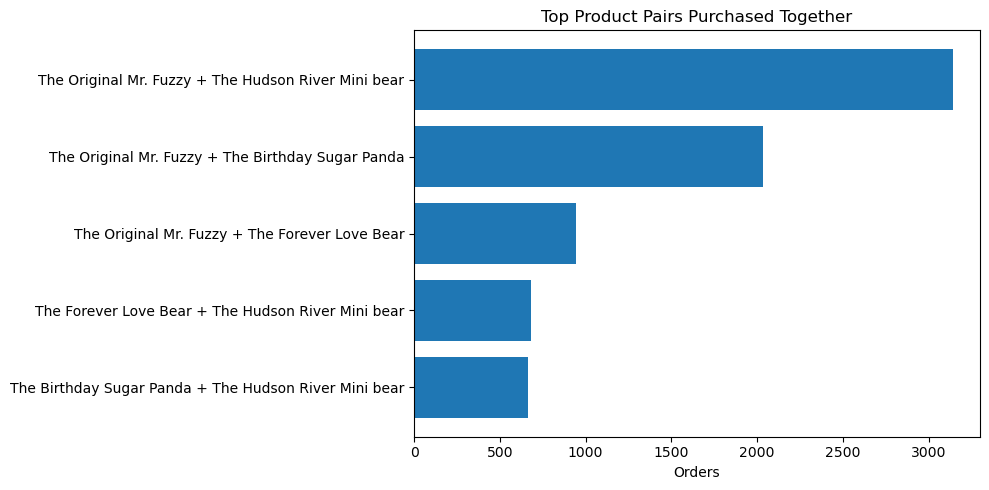

In [10]:
top_pairs = (
    two_prod
    .groupby(['product_name_a','product_name_b'])
    .agg(total_orders=('order_id','count'))
    .sort_values('total_orders', ascending=False)
    .head(5)
)

labels = [
    f"{a} + {b}"
    for a, b in top_pairs.index
]

plt.figure(figsize=(10,5))

plt.barh(
    labels[::-1],
    top_pairs['total_orders'][::-1]
)

plt.title('Top Product Pairs Purchased Together')
plt.xlabel('Orders')

plt.tight_layout()
plt.show()

### Mr. Fuzzy is central to multi-item purchasing, particularly in combination with Hudson River Mini bear and Birthday Sugar Panda.

## Is the business growing because it is acquiring more customers, or because existing customers are coming back and purchasing again?

In [11]:
orders_per_customer = orders.groupby('user_id').agg(
    total_orders=('order_id', 'count')
)

returning_customers = orders_per_customer[
    orders_per_customer['total_orders'] > 1
]

returning_customers.shape[0]

591

In [12]:
repeat_customer_rate = (returning_customers.shape[0] / orders_per_customer.shape[0]) * 100

repeat_customer_rate

1.8645885916203937

In [13]:
returning_customer_orders = returning_customers.merge(
    orders,
    on='user_id',
    how='left'
)

monthly_returning_customers = returning_customer_orders.groupby(
    returning_customer_orders['created_at'].dt.to_period('M')
).agg(
    total_returning_customers=('user_id', 'nunique')
)

monthly_returning_customers

,total_returning_customers
created_at,
2012-06,2
2012-07,1
2012-08,2
2012-09,5
2012-10,5
2012-11,9
2012-12,8
2013-01,8
2013-02,15


In [14]:
unique_customers_per_month = orders.groupby(orders['created_at'].dt.to_period('M')).agg(
    total_unique_customers=('user_id', 'nunique')
)

monthly_customer_analysis = unique_customers_per_month.join(
    monthly_returning_customers
)

monthly_customer_analysis['total_returning_customers'] = (
    monthly_customer_analysis['total_returning_customers'].fillna(0)
)

monthly_customer_analysis['returning_customer_pct'] = (
    monthly_customer_analysis['total_returning_customers'] / monthly_customer_analysis['total_unique_customers']
) * 100

monthly_customer_analysis

,total_unique_customers,total_returning_customers,returning_customer_pct
created_at,,,
2012-03,60,0.0,0.000000
2012-04,99,0.0,0.000000
2012-05,108,0.0,0.000000
2012-06,139,2.0,1.438849
2012-07,169,1.0,0.591716
2012-08,227,2.0,0.881057
2012-09,287,5.0,1.742160
2012-10,369,5.0,1.355014
2012-11,617,9.0,1.458671


### Returning customers represented a small share of the customer base overall, but their monthly share increased over time, rising from near 1% in 2012 to approximately 3–4% during 2014–2015. This indicates improving repeat-purchase participation as the business matured.

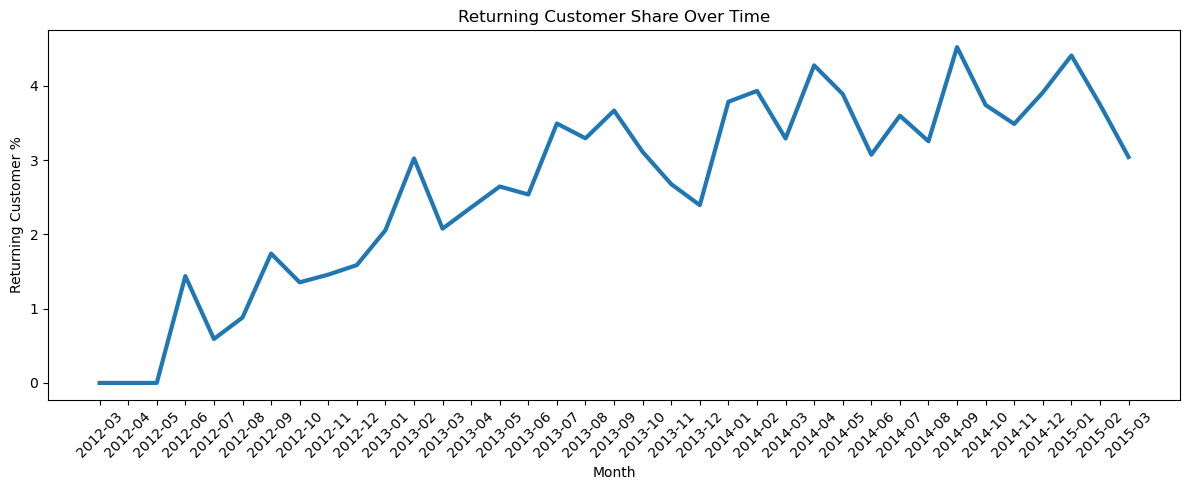

In [15]:
customer_plot = monthly_customer_analysis.copy()
customer_plot.index = customer_plot.index.astype(str)

plt.figure(figsize=(12,5))

plt.plot(
    customer_plot.index,
    customer_plot['returning_customer_pct'],
    linewidth=3
)

plt.title('Returning Customer Share Over Time')
plt.xlabel('Month')
plt.ylabel('Returning Customer %')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Which landing page performs better?

In [16]:
website_pageviews.shape
website_sessions.shape

(472871, 9)

In [17]:
first_pageview = website_pageviews.groupby('website_session_id').agg(
                    first_pageview=('created_at', 'min')
                 )

first_pageview = first_pageview.merge(
    website_pageviews, left_on=['first_pageview', 'website_session_id'], right_on=['created_at', 'website_session_id'], how='left'
)

first_pageview

,first_pageview,website_session_id,website_pageview_id,created_at,pageview_url
0,2012-03-19 08:04:16,1,1,2012-03-19 08:04:16,/home
1,2012-03-19 08:16:49,2,2,2012-03-19 08:16:49,/home
2,2012-03-19 08:26:55,3,3,2012-03-19 08:26:55,/home
3,2012-03-19 08:37:33,4,4,2012-03-19 08:37:33,/home
4,2012-03-19 09:00:55,5,5,2012-03-19 09:00:55,/home
...,...,...,...,...,...
472866,2015-03-19 07:49:25,472867,1188111,2015-03-19 07:49:25,/home
472867,2015-03-19 07:54:36,472868,1188114,2015-03-19 07:54:36,/lander-3
472868,2015-03-19 07:55:40,472869,1188116,2015-03-19 07:55:40,/lander-3
472869,2015-03-19 07:56:29,472870,1188118,2015-03-19 07:56:29,/lander-5


In [18]:
landing_pages = first_pageview[
    ['website_session_id', 'pageview_url']
]

In [19]:
landing_pages.groupby('pageview_url').agg(
    total_sessions=('website_session_id', 'count')
)

,total_sessions
pageview_url,
/home,137576
/lander-1,47574
/lander-2,131170
/lander-3,79000
/lander-4,9385
/lander-5,68166


In [20]:
landing_page_orders = landing_pages.merge(
    orders, on='website_session_id', how='left'
)

landing_page_orders

,website_session_id,pageview_url,order_id,created_at,user_id,primary_product_id,items_purchased,price_usd,cogs_usd,gross_profit,profit_margin
0,1,/home,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,/home,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,/home,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,/home,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,/home,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
472866,472867,/home,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
472867,472868,/lander-3,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
472868,472869,/lander-3,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
472869,472870,/lander-5,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
page_performance = landing_page_orders.groupby('pageview_url').agg(
                        sessions = ('website_session_id', 'count'),
                        converted_sessions = ('order_id', 'count')
                    )

page_performance['conversion_rate'] = (page_performance['converted_sessions'] / page_performance['sessions']) * 100

page_performance

,sessions,converted_sessions,conversion_rate
pageview_url,,,
/home,137576,9711,7.058644
/lander-1,47574,2157,4.533989
/lander-2,131170,10128,7.721278
/lander-3,79000,2679,3.391139
/lander-4,9385,708,7.543953
/lander-5,68166,6930,10.166359


In [22]:
baseline = page_performance.loc['/home', 'conversion_rate']

page_performance['conversion_rate_diff'] = (
    page_performance['conversion_rate'] - baseline
)

page_performance['relative_lift'] = (
    ((page_performance['conversion_rate'] - baseline) / baseline) * 100
)

page_performance

,sessions,converted_sessions,conversion_rate,conversion_rate_diff,relative_lift
pageview_url,,,,,
/home,137576,9711,7.058644,0.000000,0.000000
/lander-1,47574,2157,4.533989,-2.524655,-35.766853
/lander-2,131170,10128,7.721278,0.662634,9.387551
/lander-3,79000,2679,3.391139,-3.667505,-51.957639
/lander-4,9385,708,7.543953,0.485309,6.875388
/lander-5,68166,6930,10.166359,3.107715,44.027078


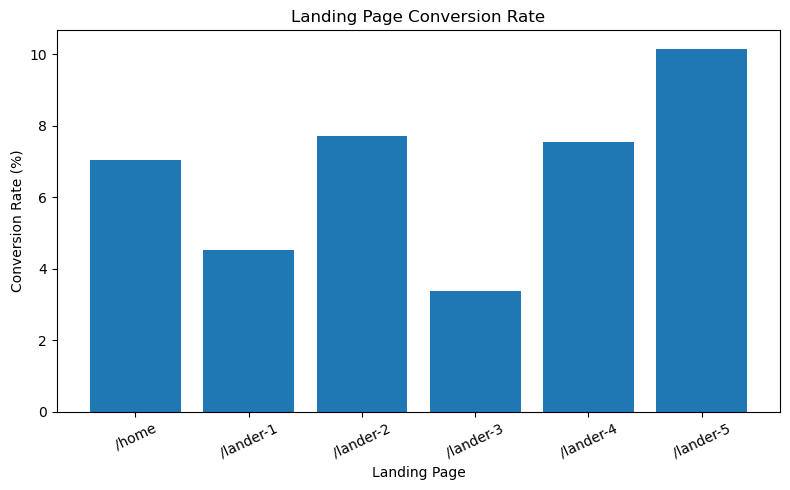

In [23]:
landing_plot = page_performance.copy()

plt.figure(figsize=(8,5))

plt.bar(
    landing_plot.index,
    landing_plot['conversion_rate']
)

plt.title('Landing Page Conversion Rate')
plt.xlabel('Landing Page')
plt.ylabel('Conversion Rate (%)')

plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

## Would a difference as large as 3.11 percentage points be reasonably expected just from that natural variation?

**H₀ (null hypothesis):**

`/home` and `/lander-5` have the same underlying conversion rate.

**H₁ (alternative hypothesis):**

`/home` and `/lander-5` have different underlying conversion rates.

In [24]:
home_conversions = page_performance.loc['/home', 'converted_sessions']
home_sessions = page_performance.loc['/home', 'sessions']

lander5_conversions = page_performance.loc['/lander-5', 'converted_sessions']
lander5_sessions = page_performance.loc['/lander-5', 'sessions']

print(f"Home Page Conversions: {home_conversions}, Home Page Sessions: {home_sessions}")
print(f"Lander 5 Conversions: {lander5_conversions}, Lander 5 Sessions: {lander5_sessions}")

Home Page Conversions: 9711, Home Page Sessions: 137576
Lander 5 Conversions: 6930, Lander 5 Sessions: 68166


In [25]:
conversions = [home_conversions, lander5_conversions]
sessions = [home_sessions, lander5_sessions]

z_stat, p_value = proportions_ztest(
    conversions,
    sessions
)

In [26]:
print("Z-statistic:", z_stat)
print("P-value:", p_value)

Z-statistic: -24.3344331578322
P-value: 8.473666320261767e-131


In [27]:
ci_low, ci_high = confint_proportions_2indep(
    count1=lander5_conversions,
    nobs1=lander5_sessions,
    count2=home_conversions,
    nobs2=home_sessions,
    method='wald'
)

print("Lower:", ci_low)
print("Upper:", ci_high)

Lower: 0.028435447962539086
Upper: 0.033718844950820996


## Landing Page Analysis — Current Conclusion

- `/home` conversion rate: **7.06%**
- `/lander-2` conversion rate: **7.72%**
- `/lander-5` conversion rate: **10.17%**

Among the six landing pages, `/lander-2` and `/lander-5` had higher observed conversion
rates than the `/home` baseline and also received substantial traffic. `/lander-1` and
`/lander-3` performed below the baseline, while `/lander-4` had relatively low traffic and
was therefore deprioritized for further investigation.

### `/lander-5` vs `/home`

- Observed difference: **+3.11 percentage points**
- Relative lift: **+44.03%**
- Two-proportion z-test: **Z = -24.33**
- p-value: **8.47 × 10⁻¹³¹**
- 95% confidence interval for `/lander-5` vs `/home`: **+2.84 to +3.37 percentage points**

The statistical test provides very strong evidence that the observed conversion rates of
`/home` and `/lander-5` differ.

However, this is a historical/observational comparison rather than a confirmed randomized
A/B experiment. Therefore, the statistical result shows a strong difference in observed
conversion rates, but does not by itself prove that the landing page caused the difference.

### Business Interpretation

`/lander-5` shows the largest observed conversion rate among the landing pages and is therefore
an important candidate for further investigation. `/lander-2` is another relevant candidate
because its conversion rate is above the `/home` baseline and it has substantial traffic.

Before interpreting these conversion differences as landing-page effects, we should investigate
whether the pages received different types of visitors.

### Next Step

Analyze **landing page × device type** for:

- `/home`
- `/lander-2`
- `/lander-5`

This will show whether these pages have noticeably different desktop/mobile traffic mixes.

If the traffic mix differs substantially, some of the observed conversion-rate difference may
be related to visitor composition rather than the landing page itself.

After this check, we will determine whether further analysis is necessary.

In [28]:
landing_page_devices = landing_pages.merge(
    website_sessions[['website_session_id', 'device_type']],
    on='website_session_id',
    how='left'
)

page_with_device_performance = landing_page_devices.groupby(
    ['pageview_url', 'device_type']
)['website_session_id'].count().reset_index()

page_with_device_performance

,pageview_url,device_type,website_session_id
0,/home,desktop,87263
1,/home,mobile,50313
2,/lander-1,desktop,37460
3,/lander-1,mobile,10114
4,/lander-2,desktop,124753
5,/lander-2,mobile,6417
6,/lander-3,mobile,79000
7,/lander-4,desktop,9385
8,/lander-5,desktop,68166


In [29]:
website_sessions['device_type'].value_counts(dropna=False)

device_type
desktop    327027
mobile     145844
Name: count, dtype: int64

In [30]:
landing_page_devices[
    landing_page_devices['pageview_url'].isin(['/home', '/lander-2', '/lander-5'])
]['device_type'].value_counts(dropna=False)

device_type
desktop    280182
mobile      56730
Name: count, dtype: int64

In [31]:
page_performance = landing_page_devices.groupby(
    'pageview_url'
)['website_session_id'].count().reset_index()

page_with_device_performance = page_with_device_performance.merge(
    page_performance, 
    on='pageview_url', 
    how='inner',
    suffixes=('_device', '_total'))

page_with_device_performance = page_with_device_performance.rename(
    columns={
        'website_session_id_device': 'device_sessions',
        'website_session_id_total': 'total_sessions'
    }
)

page_with_device_performance['device_share_pct'] = (page_with_device_performance[
    'device_sessions'
    ] / page_with_device_performance['total_sessions']) * 100

page_with_device_performance

,pageview_url,device_type,device_sessions,total_sessions,device_share_pct
0,/home,desktop,87263,137576,63.428941
1,/home,mobile,50313,137576,36.571059
2,/lander-1,desktop,37460,47574,78.740489
3,/lander-1,mobile,10114,47574,21.259511
4,/lander-2,desktop,124753,131170,95.107875
5,/lander-2,mobile,6417,131170,4.892125
6,/lander-3,mobile,79000,79000,100.000000
7,/lander-4,desktop,9385,9385,100.000000
8,/lander-5,desktop,68166,68166,100.000000


### Device Mix Insight

The landing pages did not receive the same mix of visitors.

- `/home`: 63.4% desktop, 36.6% mobile
- `/lander-2`: 95.1% desktop
- `/lander-5`: 100% desktop

This suggests that part of the observed conversion-rate difference may be influenced by differences in visitor composition, so the landing-page comparison should not be interpreted as a purely causal effect.

## Which traffic source brings the highest-quality customers?

In [32]:
traffic_performance = website_sessions.merge(
    orders, on='website_session_id', how='left'
)

source_performance = traffic_performance.groupby('utm_source').agg(
    sessions=('website_session_id', 'count'),
    orders=('order_id', 'count'),
    revenue=('price_usd', 'sum'),
    profit=('gross_profit', 'sum')
)

source_performance['conversion_rate'] = (
    source_performance['orders'] / source_performance['sessions']
) * 100

source_performance['revenue_per_session'] = (
    source_performance['revenue'] / source_performance['sessions']
)

source_performance['profit_per_session'] = (
    source_performance['profit'] / source_performance['sessions']
)

source_performance

,sessions,orders,revenue,profit,conversion_rate,revenue_per_session,profit_per_session
utm_source,,,,,,,
bsearch,71032,5262,313477.22,196628.0,7.407929,4.413183,2.768161
gsearch,351237,23852,1428149.36,895664.0,6.790856,4.066056,2.550027
socialbook,10685,343,22259.33,14102.5,3.210108,2.083232,1.319841


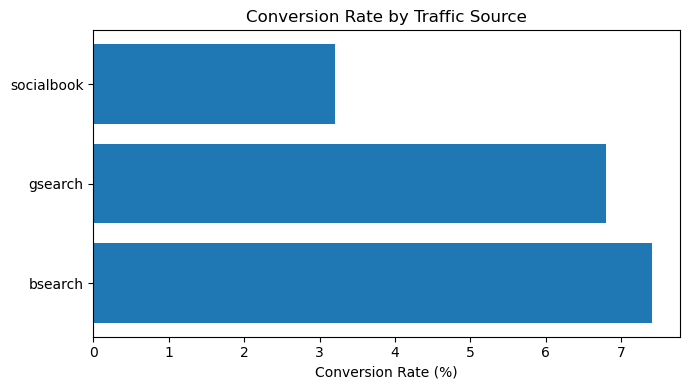

In [33]:
plt.figure(figsize=(7,4))

plt.barh(
    source_performance.index,
    source_performance['conversion_rate']
)

plt.title('Conversion Rate by Traffic Source')
plt.xlabel('Conversion Rate (%)')

plt.tight_layout()
plt.show()

### Marketing Performance Insights

The traffic sources show different strengths when evaluated by both volume and efficiency.

- **gsearch** generated the highest number of sessions, orders, revenue, and total profit, making it the primary growth driver.
- **bsearch** delivered the highest conversion rate (7.41%), revenue per session (£4.41), and profit per session (£2.77), indicating that it attracts higher-value visitors despite lower traffic volume.
- **socialbook** produced the lowest conversion rate (3.21%) and the weakest revenue and profit per visitor, suggesting lower purchase intent compared with the search channels.

### Business Interpretation

The analysis indicates that **gsearch** is the strongest channel for scaling customer acquisition, while **bsearch** is the most efficient channel on a per-visitor basis. If marketing resources were limited, bsearch would deserve attention for efficiency, whereas gsearch would remain critical for overall business growth.

## Which marketing campaign performs best within each traffic source?

In [34]:
campaign_performance = traffic_performance.groupby('utm_campaign').agg(
    sessions=('website_session_id', 'count'),
    orders=('order_id', 'count'),
    revenue=('price_usd', 'sum'),
    profit=('gross_profit', 'sum')
)

campaign_performance['conversion_rate'] = (
    campaign_performance['orders'] / campaign_performance['sessions']
) * 100

campaign_performance['revenue_per_session'] = (
    campaign_performance['revenue'] / campaign_performance['sessions']
)

campaign_performance['profit_per_session'] = (
    campaign_performance['profit'] / campaign_performance['sessions']
)

campaign_performance

,sessions,orders,revenue,profit,conversion_rate,revenue_per_session,profit_per_session
utm_campaign,,,,,,,
brand,41243,3212,194839.70,122599.0,7.787988,4.724188,2.972601
desktop_targeted,5590,288,18516.10,11720.0,5.152057,3.312361,2.096601
nonbrand,337615,22640,1349977.69,845993.5,6.705863,3.998571,2.505794
pilot,5095,55,3743.23,2382.5,1.079490,0.734687,0.467615


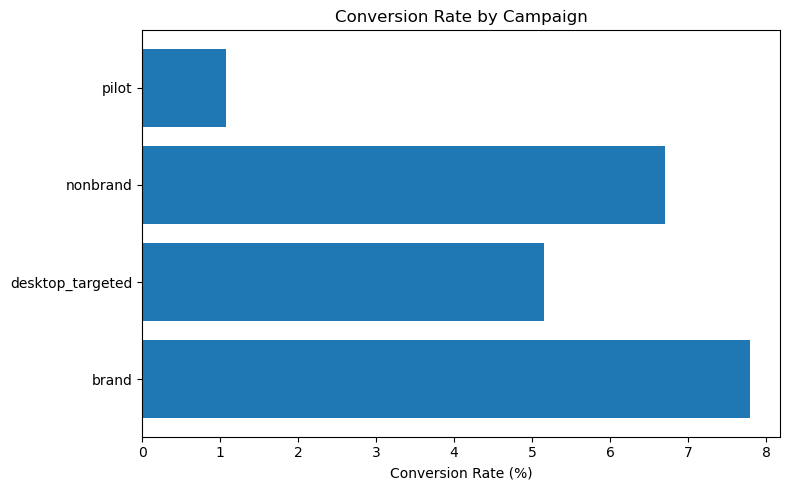

In [35]:
plt.figure(figsize=(8,5))

plt.barh(
    campaign_performance.index,
    campaign_performance['conversion_rate']
)

plt.title('Conversion Rate by Campaign')
plt.xlabel('Conversion Rate (%)')

plt.tight_layout()
plt.show()

### Campaign Performance Insights

Campaigns differ not only in traffic volume but also in customer quality.

- **Brand** achieved the highest conversion rate (7.79%) and the highest revenue and profit per session, indicating strong purchase intent.
- **Nonbrand** generated the largest number of sessions, orders, revenue, and profit, making it the primary acquisition campaign.
- **Desktop Targeted** performed moderately but at a much smaller scale.
- **Pilot** produced the weakest results across all efficiency metrics and may require optimization or budget review.

### Business Interpretation

The results suggest that **Brand** is the most efficient campaign for converting visitors, while **Nonbrand** remains the most important campaign for driving overall business growth.

## Which products generate the highest refund losses?

In [36]:
refund_analysis = order_item_refunds.merge(
    order_items, on='order_item_id', how='left'
)

refund_analysis = refund_analysis.merge(
    products, on='product_id', how='left'
)

refund_analysis = refund_analysis.groupby(
    'product_name'
).agg(
    refunds=('order_item_refund_id', 'count'),
    refund_amount=('refund_amount_usd', 'sum')
)

refund_analysis

,refunds,refund_amount
product_name,,
The Birthday Sugar Panda,301,13842.99
The Forever Love Bear,129,7738.71
The Hudson River Mini bear,64,1919.36
The Original Mr. Fuzzy,1237,61837.63


In [37]:
product_performance = order_items.merge(
    products, on='product_id', how='left'
).groupby('product_name').agg(
    units_sold=('order_item_id', 'count'),
    revenue=('price_usd', 'sum'),
    profit=('gross_profit', 'sum')
).sort_values('revenue', ascending=False)


refund_analysis = refund_analysis.merge(
    product_performance[['units_sold']],
    on='product_name',
    how='left'
)

refund_analysis['refund_rate'] = (
    refund_analysis['refunds'] / refund_analysis['units_sold']
) * 100

refund_analysis

,refunds,refund_amount,units_sold,refund_rate
product_name,,,,
The Birthday Sugar Panda,301,13842.99,4985,6.038114
The Forever Love Bear,129,7738.71,5796,2.225673
The Hudson River Mini bear,64,1919.36,5018,1.275409
The Original Mr. Fuzzy,1237,61837.63,24226,5.106084


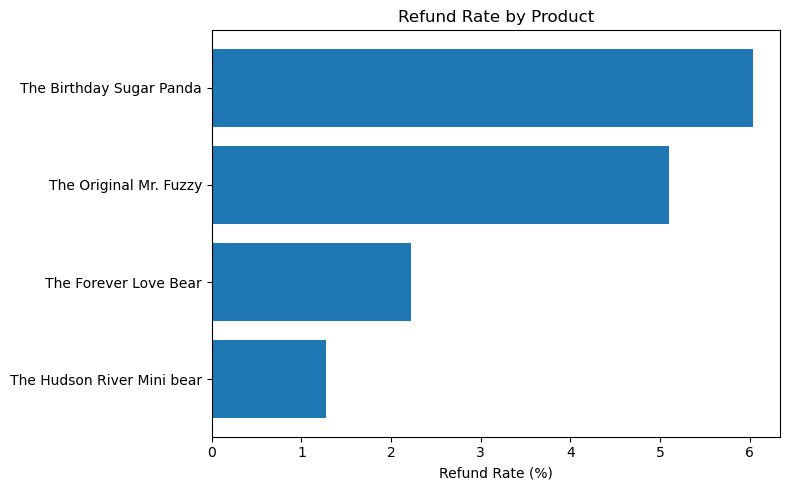

In [38]:
refund_plot = refund_analysis.sort_values('refund_rate', ascending=True)

plt.figure(figsize=(8,5))

plt.barh(
    refund_plot.index,
    refund_plot['refund_rate']
)

plt.title('Refund Rate by Product')
plt.xlabel('Refund Rate (%)')

plt.tight_layout()
plt.show()

### Refund Performance Insights

Refund behavior differs substantially when sales volume is taken into account.

- **The Birthday Sugar Panda** has the highest refund rate (6.04%), making it the strongest indicator of a potential product-quality or customer-experience issue.
- **The Original Mr. Fuzzy** generates the largest total refund loss (£61,837.63), but its refund rate (5.11%) is lower than Birthday Sugar Panda because it sells at much higher volume.
- **The Hudson River Mini Bear** has the lowest refund rate (1.28%), indicating stronger post-purchase performance.

### Business Interpretation

Evaluating both refund amount and refund rate provides a more balanced assessment of product performance. Products with high refund rates deserve quality or customer-experience investigation, while products with high refund amounts have the greatest financial impact on the business.

# Executive Summary

### Key Findings

- Revenue increased consistently over the analysis period.
- Two-item purchasing became more common, contributing to higher order values.
- Mr. Fuzzy dominated multi-item purchasing behavior.
- Returning-customer participation increased over time.
- Lander-5 showed the highest observed conversion rate (+44% relative lift vs Home), although device mix should be considered.
- Bsearch delivered the highest conversion efficiency.
- Brand campaigns converted best, while Nonbrand generated the largest overall revenue.
- Birthday Sugar Panda had the highest refund rate, while Mr. Fuzzy generated the largest refund losses.